## 1. Load the image dataset, preprocess images and split the data into training and validation sets.


In [1]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

In [2]:
tf.random.set_seed(123)
np.random.seed(123)

In [4]:
dataset_url = "https://storage.googleapis.com/download.tensorflow.org/example_images/flower_photos.tgz"

dataset_path = tf.keras.utils.get_file(
    fname="flower_photos.tgz",
    origin=dataset_url,
    extract=True,
    cache_subdir="datasets"
)

228813984/228813984 ━━━━━━━━━━━━━━━━━━━━ 17s 0us/step


In [5]:
expected_classes = {
    "daisy", "dandelion", "roses", "sunflowers", "tulips"
}

search_roots = [
    Path.home() / ".keras" / "datasets",
    Path(dataset_path).parent,
    Path.cwd()
]

data_dir = None

for root in search_roots:
    if root.exists():
        candidates = [root] + list(root.rglob("flower_photos"))

        for candidate in candidates:
            if candidate.is_dir():
                folders = {
                    p.name for p in candidate.iterdir() if p.is_dir()
                }

                if expected_classes.issubset(folders):
                    data_dir = candidate
                    break

    if data_dir is not None:
        break

if data_dir is None:
    raise FileNotFoundError(
        "Flower dataset folder not found. Check the download and extraction."
    )

print("Dataset path:", data_dir)

Dataset path: C:\Users\Acer\.keras\datasets\flower_photos\flower_photos


In [6]:
IMAGE_SIZE = (96, 96)
BATCH_SIZE = 16
MAX_IMAGES_PER_CLASS = 100

full_ds = tf.keras.utils.image_dataset_from_directory(
    data_dir,
    image_size=IMAGE_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="int",
    shuffle=True,
    seed=123
)

class_names = full_ds.class_names
num_classes = len(class_names)

print("Classes:", class_names)

Found 3670 files belonging to 5 classes.
Classes: ['daisy', 'dandelion', 'roses', 'sunflowers', 'tulips']


In [7]:
images_list = []
labels_list = []
class_counts = {i: 0 for i in range(num_classes)}

for image_batch, label_batch in full_ds:
    for image, label in zip(image_batch, label_batch):
        label_id = int(label.numpy())

        if class_counts[label_id] < MAX_IMAGES_PER_CLASS:
            images_list.append(image.numpy().astype(np.uint8))
            labels_list.append(label_id)
            class_counts[label_id] += 1

    if all(
        count >= MAX_IMAGES_PER_CLASS
        for count in class_counts.values()
    ):
        break

X = np.array(images_list, dtype=np.uint8)
y = np.array(labels_list, dtype=np.int32)

print("Dataset shape:", X.shape)
print("Images per class:", {
    class_names[k]: v for k, v in class_counts.items()
})

Dataset shape: (500, 96, 96, 3)
Images per class: {'daisy': 100, 'dandelion': 100, 'roses': 100, 'sunflowers': 100, 'tulips': 100}


In [8]:
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.30, random_state=123, stratify=y
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, random_state=123, stratify=y_temp
)

print("Training images:", X_train.shape)
print("Validation images:", X_val.shape)
print("Testing images:", X_test.shape)

Training images: (350, 96, 96, 3)
Validation images: (75, 96, 96, 3)
Testing images: (75, 96, 96, 3)


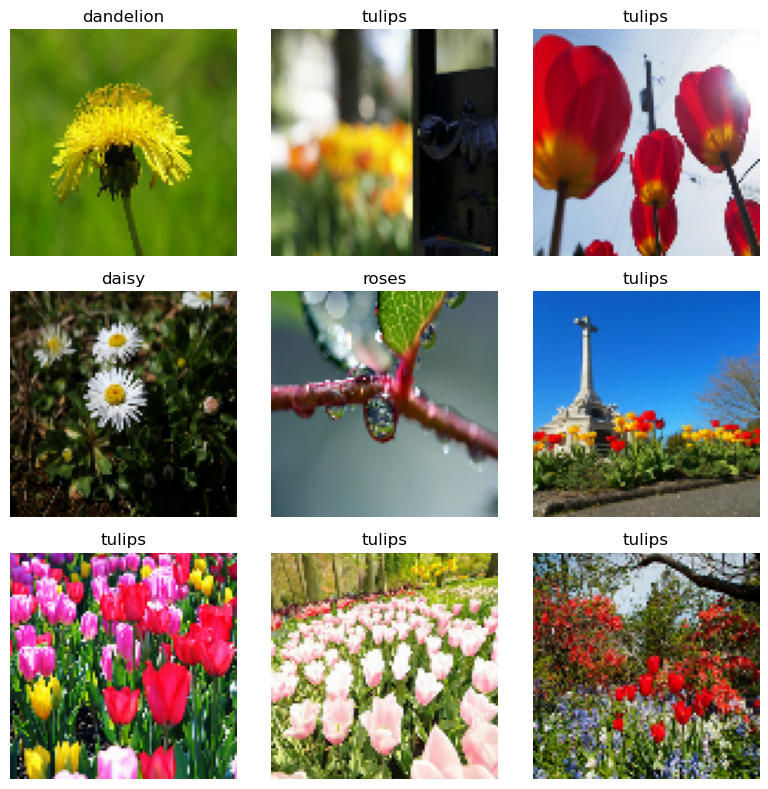

In [11]:
plt.figure(figsize=(8, 8))

for i in range(min(9, len(X_train))):
    plt.subplot(3, 3, i + 1)
    plt.imshow(X_train[i])

    label_index = int(y_train[i])
    plt.title(class_names[label_index])
    plt.axis("off")

plt.tight_layout()
plt.show()

In [12]:
AUTOTUNE = tf.data.AUTOTUNE

train_ds = tf.data.Dataset.from_tensor_slices(
    (X_train, y_train)
)

train_ds = (
    train_ds
    .shuffle(min(len(X_train), 500), seed=123)
    .batch(BATCH_SIZE)
    .prefetch(AUTOTUNE)
)

val_ds = tf.data.Dataset.from_tensor_slices(
    (X_val, y_val)
)

val_ds = val_ds.batch(BATCH_SIZE).prefetch(AUTOTUNE)

test_ds = tf.data.Dataset.from_tensor_slices(
    (X_test, y_test)
)

test_ds = test_ds.batch(BATCH_SIZE).prefetch(AUTOTUNE)

## 2. Build the CNN model

In [13]:
model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(96, 96, 3)),
    tf.keras.layers.Rescaling(1.0 / 255),

    tf.keras.layers.Conv2D(
        16, (3, 3), activation="relu"
    ),
    tf.keras.layers.MaxPooling2D(),

    tf.keras.layers.Conv2D(
        32, (3, 3), activation="relu"
    ),
    tf.keras.layers.MaxPooling2D(),

    tf.keras.layers.Conv2D(
        64, (3, 3), activation="relu"
    ),
    tf.keras.layers.MaxPooling2D(),

    tf.keras.layers.GlobalAveragePooling2D(),
    tf.keras.layers.Dense(64, activation="relu"),
    tf.keras.layers.Dropout(0.3),

    tf.keras.layers.Dense(
        num_classes, activation="softmax"
    )
])

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling (Rescaling)           │ (None, 96, 96, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 94, 94, 16)     │           448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 47, 47, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 45, 45, 32)     │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 22, 22, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 20, 20, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 10, 10, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 64)             │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │         4,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 5)              │           325 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 28,069 (109.64 KB)

 Trainable params: 28,069 (109.64 KB)

 Non-trainable params: 0 (0.00 B)

## 3. Compile and Train the model

In [14]:
model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling (Rescaling)           │ (None, 96, 96, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 94, 94, 16)     │           448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 47, 47, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 45, 45, 32)     │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 22, 22, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 20, 20, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 10, 10, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 64)             │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │         4,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 5)              │           325 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 28,069 (109.64 KB)

 Trainable params: 28,069 (109.64 KB)

 Non-trainable params: 0 (0.00 B)

In [15]:
EPOCHS = 15

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS
)

Epoch 1/15


d:\anaconda3\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


22/22 ━━━━━━━━━━━━━━━━━━━━ 2s 19ms/step - accuracy: 0.2229 - loss: 1.6003 - val_accuracy: 0.3733 - val_loss: 1.5593
Epoch 2/15
22/22 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - accuracy: 0.3343 - loss: 1.5390 - val_accuracy: 0.3467 - val_loss: 1.4873
Epoch 3/15
22/22 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.3257 - loss: 1.4854 - val_accuracy: 0.4667 - val_loss: 1.4533
Epoch 4/15
22/22 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.3286 - loss: 1.4335 - val_accuracy: 0.4133 - val_loss: 1.3875
Epoch 5/15
22/22 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.3886 - loss: 1.3952 - val_accuracy: 0.4800 - val_loss: 1.2869
Epoch 6/15
22/22 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.4371 - loss: 1.2764 - val_accuracy: 0.4667 - val_loss: 1.2420
Epoch 7/15
22/22 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.4286 - loss: 1.2225 - val_accuracy: 0.4933 - val_loss: 1.2004
Epoch 8/15
22/22 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.4886 - loss: 1.1886 - val_accuracy: 0.3733 - val_loss: 1.

## 4. Evaluate the model

In [17]:
test_loss, test_accuracy = model.evaluate(test_ds, verbose=1)

print("Test Loss:", round(test_loss, 4))
print("Test Accuracy:", round(test_accuracy * 100, 2), "%")

5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.6667 - loss: 1.0788 
Test Loss: 1.0788
Test Accuracy: 66.67 %


In [21]:
y_true = []
y_pred = []

for image_batch, label_batch in test_ds:
    prediction = model.predict(image_batch, verbose=0)
    predicted_labels = np.argmax(prediction, axis=1)

    y_true.extend(label_batch.numpy().tolist())
    y_pred.extend(predicted_labels.tolist())

print(classification_report(
    y_true,
    y_pred,
    labels=list(range(num_classes)),
    target_names=class_names,
    zero_division=0
))


              precision    recall  f1-score   support

       daisy       0.62      0.87      0.72        15
   dandelion       0.80      0.53      0.64        15
       roses       0.90      0.60      0.72        15
  sunflowers       0.63      0.80      0.71        15
      tulips       0.53      0.53      0.53        15

    accuracy                           0.67        75
   macro avg       0.70      0.67      0.66        75
weighted avg       0.70      0.67      0.66        75



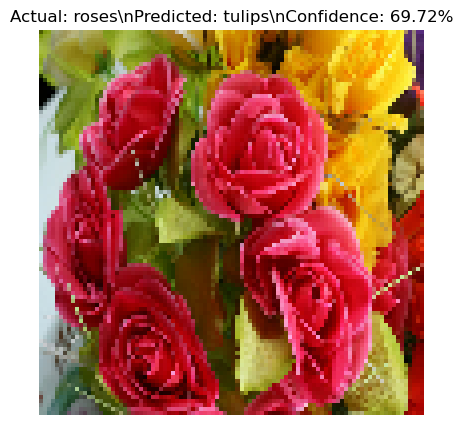

Actual Flower: roses
Predicted Flower: tulips
Confidence: 69.72%


In [23]:
sample_index = min(10, len(X_test) - 1)

sample_image = X_test[sample_index]
actual_label = int(y_test[sample_index])

prediction = model.predict(
    np.expand_dims(sample_image, axis=0),
    verbose=0
)

predicted_label = int(np.argmax(prediction[0]))
confidence = float(np.max(prediction[0])) * 100

plt.figure(figsize=(5, 5))
plt.imshow(sample_image)
plt.title(
    f"Actual: {class_names[actual_label]}\\n"
    f"Predicted: {class_names[predicted_label]}\\n"
    f"Confidence: {confidence:.2f}%"
)
plt.axis("off")
plt.show()

print("Actual Flower:", class_names[actual_label])
print("Predicted Flower:", class_names[predicted_label])
print(f"Confidence: {confidence:.2f}%")

## 5. Analyze the model's performance

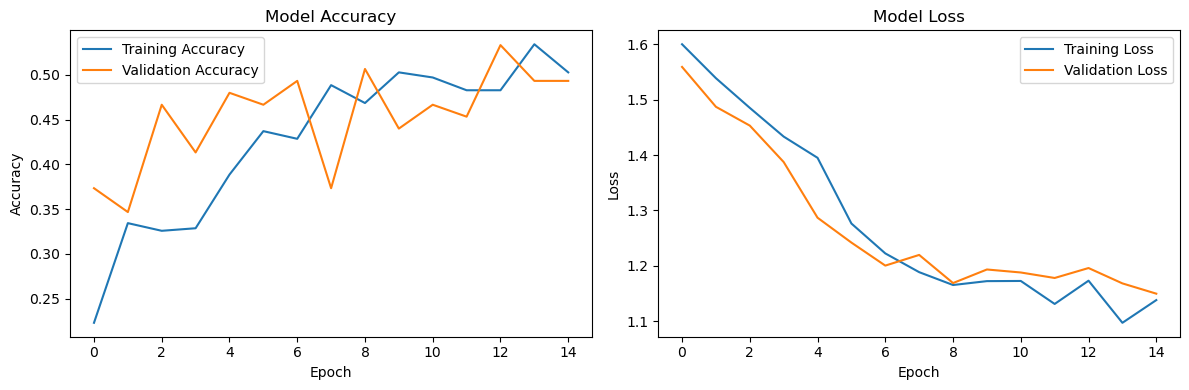

Saved trained_model.h5, trained_model.keras, and output_images.


In [24]:
import os

os.makedirs("output_images", exist_ok=True)

model.save("trained_model.h5")
model.save("trained_model.keras")

plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")
plt.title("Model Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.title("Model Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()

plt.tight_layout()
plt.savefig("output_images/training_validation_curves.png", dpi=150)
plt.show()


print("Saved trained_model.h5, trained_model.keras, and output_images.")

## Performance analysis and improvements (Task 5)

- **Test accuracy:** 66.67%
- **Test loss:** 1.0788
- **Best-performing class:** Daisy and roses, both with an F1-score of 0.72.
- **Classes most often confused:** Cannot be confirmed without the confusion matrix.
- **What the accuracy/loss curves show:** Training accuracy generally increased and training loss decreased. Validation accuracy fluctuated and reached approximately 53.33%, while validation loss generally decreased. This suggests the model learned useful patterns, but its generalization performance could be improved.
- **Two improvements to try:**
  1. Apply image augmentation, such as random flips and rotations.
  2. Try a pretrained model such as MobileNetV2.

## Conclusion

This notebook follows the mentor's array-based CNN workflow and extends it to include model evaluation and performance analysis. The model achieved a test accuracy of 66.67% and a test loss of 1.0788. Image augmentation, additional training images, and pretrained models could help improve classification accuracy and generalization. Run all cells before submission to ensure the notebook contains the actual model metrics, predictions, and plots.